In [1]:
import pandas as pd
import mlflow
import mlflow.sklearn
from pathlib import Path
import os
import mlflow

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
df_model = pd.read_csv("/Users/vijaypatidar/vijay/Anshul/deliver time prediction/data/food_delivery_processed.csv")
df_model.sample(4)

,Delivery_person_Age,Delivery_person_Ratings,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),Delivery_Distance,Order_Hour,Order_Minute,Day_of_Week,Month,Is_Weekend
4995,36.0,4.4,Sunny,Medium,0,Snack,motorcycle,1.0,No,Urban,33,12.464226,18.0,51.0,Saturday,3,1
4589,22.0,4.8,Windy,Jam,1,Drinks,motorcycle,0.0,No,Metropolitian,12,7.601266,20.0,54.0,Thursday,3,0
30073,23.0,4.5,Windy,Low,2,Meal,scooter,0.0,No,Metropolitian,12,1.552415,10.0,28.0,Monday,3,0
19301,24.0,5.0,Stormy,Jam,2,Snack,electric_scooter,0.0,No,Metropolitian,11,8.988079,21.0,13.0,Friday,2,0


In [2]:
df_model.isnull().sum()

Delivery_person_Age        0
Delivery_person_Ratings    0
Weatherconditions          0
Road_traffic_density       0
Vehicle_condition          0
Type_of_order              0
Type_of_vehicle            0
multiple_deliveries        0
Festival                   0
City                       0
Time_taken(min)            0
Delivery_Distance          0
Order_Hour                 0
Order_Minute               0
Day_of_Week                0
Month                      0
Is_Weekend                 0
dtype: int64

In [3]:
X = df_model.drop(columns="Time_taken(min)")
y = df_model["Time_taken(min)"]

In [4]:
print(X.shape)
print(y.shape)

(40353, 16)
(40353,)


In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [6]:
print("X Train :", X_train.shape)
print("X Test :", X_test.shape)
print("Y Train :", y_train.shape)
print("Y Test :", y_test.shape)

X Train : (32282, 16)
X Test : (8071, 16)
Y Train : (32282,)
Y Test : (8071,)


In [7]:
df_model.sample(5)

,Delivery_person_Age,Delivery_person_Ratings,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),Delivery_Distance,Order_Hour,Order_Minute,Day_of_Week,Month,Is_Weekend
9497,28.0,4.9,Cloudy,Low,0,Snack,motorcycle,0.0,No,Metropolitian,17,4.657580,23.0,18.0,Saturday,3,1
18901,29.0,4.9,Sandstorms,Medium,1,Buffet,scooter,1.0,No,Metropolitian,20,13.405884,17.0,53.0,Monday,4,0
14987,38.0,4.3,Fog,Jam,1,Buffet,motorcycle,1.0,No,Metropolitian,35,7.325559,20.0,47.0,Sunday,2,1
9496,24.0,4.9,Stormy,High,1,Meal,scooter,1.0,No,Urban,21,5.969081,12.0,59.0,Thursday,2,0
10762,31.0,4.2,Fog,Medium,2,Drinks,scooter,1.0,No,Metropolitian,41,19.916433,18.0,47.0,Thursday,3,0


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

In [9]:
from sklearn.preprocessing import OneHotEncoder

onehot_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [10]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_pipeline = Pipeline([
    (
        "ordinal",
        OrdinalEncoder(
            categories=[["Low", "Medium", "High", "Jam"]]
        )
    )
])

In [11]:
numerical_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "Delivery_Distance",
    "Order_Hour",
    "Order_Minute",
    "Month",
    "Is_Weekend"
]

onehot_features = [
    "Weatherconditions",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City",
    "Day_of_Week"
]

ordinal_features = [
    "Road_traffic_density"
]

In [12]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numerical_features),
        ("cat", onehot_pipeline, onehot_features),
        ("traffic", ordinal_pipeline, ordinal_features),
    ]
)

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

In [14]:
num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

In [15]:
cat_pipeline = Pipeline([
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [16]:
traffic_pipeline = Pipeline([
    (
        "ordinal",
        OrdinalEncoder(
            categories=[
                [
                    "Low",
                    "Medium",
                    "High",
                    "Jam"
                ]
            ]
        )
    )
])

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            num_pipeline,
            numerical_features
        ),
        (
            "cat",
            cat_pipeline,
            onehot_features
        ),
        (
            "traffic",
            traffic_pipeline,
            ordinal_features
        )
    ],
    remainder="drop"
)

In [18]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e

In [19]:
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [20]:
print(X_train_processed.shape)
print(X_test_processed.shape)

(32282, 35)
(8071, 35)


In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [22]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [23]:
model_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [24]:
y_pred = model_pipeline.predict(X_test)

In [25]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
comparison.head(5)

,Actual,Predicted
0,17,21.481793
1,31,23.769758
2,24,23.080871
3,48,48.210317
4,28,23.502333


In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [27]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE :", mae)

MAE : 4.790407906372123


In [28]:
mse = mean_squared_error(y_test, y_pred)
print("MSE :", mse)

MSE : 35.835551667839034


In [29]:
r2 = r2_score(y_test, y_pred)
print("R2 Score :", r2)

R2 Score : 0.592702179847473


In [30]:
from pathlib import Path
import os

print("Current directory:", Path.cwd())
print("Current user:", os.environ.get("USER"))
print("Current directory writable:", os.access(Path.cwd(), os.W_OK))

Current directory: /Users/vijaypatidar/vijay/Anshul/deliver time prediction/notebooks
Current user: vijaypatidar
Current directory writable: True


In [31]:

from pathlib import Path
import mlflow

# Close any leftover active MLflow runs
while mlflow.active_run() is not None:
    mlflow.end_run(status="KILLED")

# Resolve project root
CURRENT_DIR = Path.cwd().resolve()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Dedicated writable directory for MLflow
MLFLOW_DIR = PROJECT_ROOT / "mlflow_data"
MLFLOW_DIR.mkdir(parents=True, exist_ok=True)

# SQLite database
MLFLOW_DB = MLFLOW_DIR / "mlflow.db"

# Check directory write access
if not MLFLOW_DIR.is_dir():
    raise RuntimeError(f"MLflow directory not found: {MLFLOW_DIR}")

if not os.access(MLFLOW_DIR, os.W_OK):
    raise PermissionError(
        f"MLflow directory is not writable: {MLFLOW_DIR}"
    )

tracking_uri = f"sqlite:///{MLFLOW_DB.as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

mlflow.set_experiment("food-delivery-time-prediction")

print("Project root:", PROJECT_ROOT)
print("MLflow directory:", MLFLOW_DIR)
print("Database:", MLFLOW_DB)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment configured successfully!")



Project root: /Users/vijaypatidar/vijay/Anshul/deliver time prediction
MLflow directory: /Users/vijaypatidar/vijay/Anshul/deliver time prediction/mlflow_data
Database: /Users/vijaypatidar/vijay/Anshul/deliver time prediction/mlflow_data/mlflow.db
Tracking URI: sqlite:////Users/vijaypatidar/vijay/Anshul/deliver time prediction/mlflow_data/mlflow.db
Experiment configured successfully!


In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_estimators=100
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}
results = []
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

In [33]:
results_df.sort_values(
    by="R2 Score",
    ascending=False,
    inplace=True
)
results_df

,Model,MAE,RMSE,R2 Score
2,Random Forest,3.078082,3.821703,0.833999
3,Gradient Boosting,3.504948,4.362669,0.783677
1,Decision Tree,4.061578,5.320609,0.678248
0,Linear Regression,4.790408,5.986280,0.592702


In [34]:

# Log the existing model comparison results in MLflow

for _, row in results_df.iterrows():

    model_name = row["Model"]

    with mlflow.start_run(run_name=f"comparison-{model_name}"):

        mlflow.log_param("model_name", model_name)

        mlflow.log_metric("mae", float(row["MAE"]))
        mlflow.log_metric("rmse", float(row["RMSE"]))
        mlflow.log_metric("r2_score", float(row["R2 Score"]))

        # Log model parameters
        model_params = models[model_name].get_params()

        for param_name, param_value in model_params.items():
            if isinstance(param_value, (str, int, float, bool)):
                mlflow.log_param(param_name, param_value)

print("All model comparison results logged successfully!")


All model comparison results logged successfully!


In [35]:
runs_df = mlflow.search_runs(
    experiment_names=["food-delivery-time-prediction"]
)

print("Total runs:", len(runs_df))

display(
    runs_df[
        [
            "tags.mlflow.runName",
            "metrics.mae",
            "metrics.rmse",
            "metrics.r2_score",
        ]
    ]
)

Total runs: 19


,tags.mlflow.runName,metrics.mae,metrics.rmse,metrics.r2_score
0,comparison-Linear Regression,4.790408,5.986280,0.592702
1,comparison-Decision Tree,4.061578,5.320609,0.678248
2,comparison-Gradient Boosting,3.504948,4.362669,0.783677
3,comparison-Random Forest,3.078082,3.821703,0.833999
4,comparison-Linear Regression,4.790408,5.986280,0.592702
5,comparison-Decision Tree,4.061578,5.320609,0.678248
6,comparison-Gradient Boosting,3.504948,4.362669,0.783677
7,comparison-Random Forest,3.078082,3.821703,0.833999
8,final-random-forest,3.078082,3.821703,0.833999
9,final-random-forest,3.078082,3.821703,0.833999


In [36]:
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestRegressor(
            random_state=42
        )
    )
])
best_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [56]:

final_runs = mlflow.search_runs(
    experiment_names=["food-delivery-time-prediction"],
    filter_string="tags.mlflow.runName = 'final-random-forest'",
    order_by=["start_time DESC"],
    max_results=1
)

if final_runs.empty:
    print("Final run not found.")
else:
    run_id = final_runs.iloc[0]["run_id"]

    print("Final Run ID:", run_id)
    print("MAE:", final_runs.iloc[0]["metrics.mae"])
    print("RMSE:", final_runs.iloc[0]["metrics.rmse"])
    print("R2 Score:", final_runs.iloc[0]["metrics.r2_score"])

    artifacts = mlflow.artifacts.list_artifacts(run_id)
    print("\nLogged artifacts:")
    for artifact in artifacts:
        print("-", artifact.path)


Final Run ID: 41855530565e44eaa9698e1f7d25d377
MAE: 3.078082022054268
RMSE: 3.8217031889626543
R2 Score: 0.8339985427096637

Logged artifacts:


In [57]:

runs_df = mlflow.search_runs(
    experiment_names=["food-delivery-time-prediction"]
)

display(
    runs_df[
        [
            "tags.mlflow.runName",
            "metrics.mae",
            "metrics.rmse",
            "metrics.r2_score"
        ]
    ].sort_values("metrics.mae")
)


,tags.mlflow.runName,metrics.mae,metrics.rmse,metrics.r2_score
9,final-random-forest,3.078082,3.821703,0.833999
14,comparison-Random Forest,3.078082,3.821703,0.833999
10,final-random-forest,3.078082,3.821703,0.833999
8,final-random-forest,3.078082,3.821703,0.833999
7,comparison-Random Forest,3.078082,3.821703,0.833999
18,comparison-Random Forest,3.078082,3.821703,0.833999
3,comparison-Random Forest,3.078082,3.821703,0.833999
6,comparison-Gradient Boosting,3.504948,4.362669,0.783677
17,comparison-Gradient Boosting,3.504948,4.362669,0.783677
2,comparison-Gradient Boosting,3.504948,4.362669,0.783677


In [39]:
rf = best_pipeline.named_steps["model"]

In [40]:
importance = rf.feature_importances_

In [41]:
feature_names = best_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

In [42]:
feature_names

array(['num__Delivery_person_Age', 'num__Delivery_person_Ratings',
       'num__Vehicle_condition', 'num__multiple_deliveries',
       'num__Delivery_Distance', 'num__Order_Hour', 'num__Order_Minute',
       'num__Month', 'num__Is_Weekend', 'cat__Weatherconditions_Cloudy',
       'cat__Weatherconditions_Fog', 'cat__Weatherconditions_Sandstorms',
       'cat__Weatherconditions_Stormy', 'cat__Weatherconditions_Sunny',
       'cat__Weatherconditions_Windy', 'cat__Type_of_order_Buffet',
       'cat__Type_of_order_Drinks', 'cat__Type_of_order_Meal',
       'cat__Type_of_order_Snack',
       'cat__Type_of_vehicle_electric_scooter',
       'cat__Type_of_vehicle_motorcycle', 'cat__Type_of_vehicle_scooter',
       'cat__Festival_No', 'cat__Festival_Yes', 'cat__City_Metropolitian',
       'cat__City_Semi-Urban', 'cat__City_Urban',
       'cat__Day_of_Week_Friday', 'cat__Day_of_Week_Monday',
       'cat__Day_of_Week_Saturday', 'cat__Day_of_Week_Sunday',
       'cat__Day_of_Week_Thursday', 'cat__D

In [43]:
importance = best_pipeline.named_steps[
    "model"
].feature_importances_
importance

array([0.09324056, 0.21098556, 0.0684752 , 0.12002935, 0.12277645,
       0.01065697, 0.02700258, 0.00526207, 0.00217644, 0.03984259,
       0.04233012, 0.00275976, 0.00276339, 0.06923558, 0.00289463,
       0.00309431, 0.00309327, 0.00313965, 0.00309387, 0.00119503,
       0.00168769, 0.00184065, 0.00511385, 0.00494645, 0.0025719 ,
       0.00162858, 0.00243345, 0.00269972, 0.00253384, 0.00205546,
       0.00222498, 0.00280374, 0.00272616, 0.00290887, 0.12777731])

In [44]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

In [45]:
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
importance_df

,Feature,Importance
1,num__Delivery_person_Ratings,0.210986
34,traffic__Road_traffic_density,0.127777
4,num__Delivery_Distance,0.122776
3,num__multiple_deliveries,0.120029
0,num__Delivery_person_Age,0.093241
13,cat__Weatherconditions_Sunny,0.069236
2,num__Vehicle_condition,0.068475
10,cat__Weatherconditions_Fog,0.042330
9,cat__Weatherconditions_Cloudy,0.039843
6,num__Order_Minute,0.027003


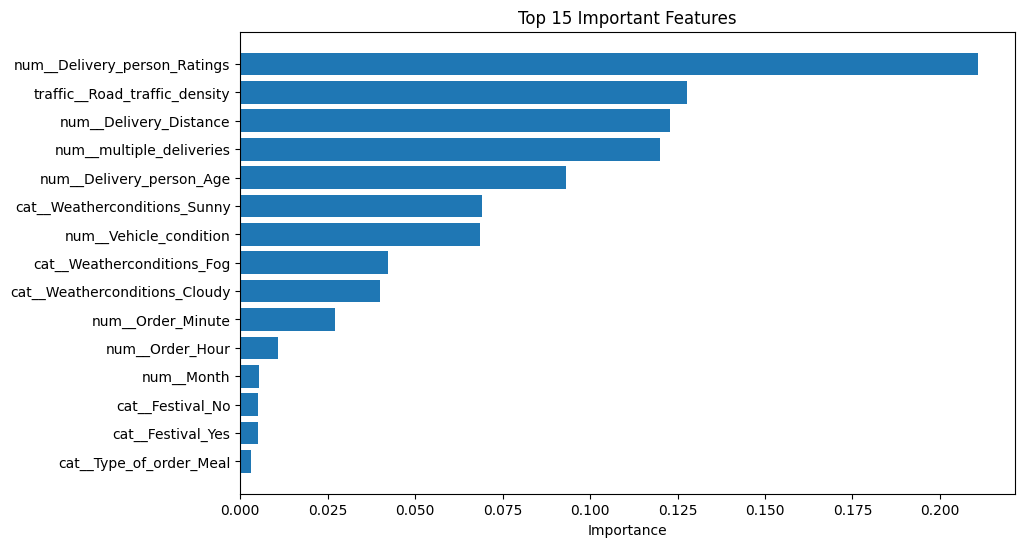

In [46]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")

plt.title("Top 15 Important Features")

plt.show()

In [47]:
import os
import joblib

model_path = "../models/best_food_delivery_model.pkl"

os.makedirs(os.path.dirname(model_path), exist_ok=True)

if not os.path.exists(model_path):
    joblib.dump(best_pipeline, model_path)
    print("Model saved successfully!")
else:
    print("Model already exists. Skipping save.")

Model already exists. Skipping save.


In [48]:
# print("Model type:")
# print(type(best_pipeline))

# print("\nPipeline steps:")
# print(best_pipeline.named_steps.keys())

# print("\nExpected input features:")
# print(best_pipeline.feature_names_in_)

# print("\nNumber of input features:")
# print(len(best_pipeline.feature_names_in_))

In [49]:
# print(X_train.columns.tolist())

In [50]:
# for col in [
#     "Weatherconditions",
#     "Road_traffic_density",
#     "Type_of_order",
#     "Type_of_vehicle",
#     "Festival",
#     "City",
#     "Day_of_Week",
# ]:
#     print(f"\n{col}:")
#     print(sorted(df_model[col].dropna().unique(), key=str))